<a id="top"></a>
# Лабораторная работа № 1. Статистический анализ свойств материалов
## Спринт 1: пьезоэлектрики и диэлектрики

В работе используются два датасета и исследуются две случайные величины:
1. Максимальный пьезоэлектрический коэффициент $e_{ij}^{\max}$, Кл/м² — 941 запись из базы de Jong et al.
2. Показатель преломления $n$ — 4764 записи Matbench `matbench_dielectric`.

Объём на атом из первого датасета используется только как структурный признак.

[Данные и подготовка](#data) · [Пьезокоэффициент](#rv1) · [Показатель преломления](#rv2) · [Итоги](#resume) · [Источники](#refs)


<a id="data"></a>
## Данные и подготовка

| Датасет | Файл | Наблюдений | Используемые поля |
|---|---|---:|---|
| de Jong et al., база пьезоэлектрических материалов | `data/piezo.json` | 941 | $e_{ij}^{\max}$, состав, симметрия, объём и число атомов |
| Matbench `matbench_dielectric`, таблица с предсказаниями MODNet | `data/matbench_dielectric_n_folds.csv` | 4764 | $n$, предсказание модели, номер тестового фолда |

Единица наблюдения в первом наборе - запись о кристаллической структуре: одинаковый состав может встречаться в разных структурах. Во втором наборе каждая строка содержит целевое значение и сохранённое предсказание. Качество MODNet оценивается по сохранённым предсказаниям. Модель заново не обучается; проверить исходную процедуру обучения и формирования фолдов по этим файлам нельзя.

Данные загружаются из локальных файлов. Перед анализом проверяется число строк, идентификаторы, пропуски и допустимость числовых значений. Экстремальные наблюдения сохраняются. Состав разбирается с учётом скобок. Признаки состава - средние атомный номер, масса и электроотрицательность, наличие кислорода и галогенов. Если электроотрицательность хотя бы одного элемента неизвестна, среднее помечается пропуском; такие строки исключаются только из соответствующей CV-проверки.

Метка «с потенциально токсичными элементами» означает присутствие Pb, Cd, Hg, Tl, As и/или Be. Это рабочая группировка состава: она не учитывает химическую форму, дозу и условия применения.

Для $e_{ij}^{\max}$ и объёма на атом доступны парные параметры.


In [1]:
import numpy as np, pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
import statlib as S, piezo_data as P

S.set_style(); pd.set_option('display.precision', 4); pd.set_option('display.width', 170)
SEED = S.RNG_SEED
piezo = P.load_piezo(); diel = P.load_dielectric()
x1, x2 = piezo.eij_max.values, diel.n.values
audit = P.validate_data(piezo, diel)
display(audit)
pd.DataFrame({'N': [len(x1), len(x2)], 'ед.': ['Кл/м²', '—']}, index=['e_ij_max', 'n'])

,датасет,N,повторных id,пропусков в целевых полях,строк с пропуском EN
0,piezo,941,0,0,6
1,dielectric,4764,0,0,0


,N,ед.
e_ij_max,941,Кл/м²
n,4764,—


In [2]:
display(piezo[['formula','pg','nsites','volume','vol_atom','eij_max','toxic','has_O']].head(6))
print('уникальных формул:', piezo.formula.nunique(), 'из', len(piezo), '— остальные записи — разные структуры того же состава')

,formula,pg,nsites,volume,vol_atom,eij_max,toxic,has_O
0,AgI,-43m,2,73.2196,36.6098,0.0915,False,False
1,CdTe,-43m,2,72.8272,36.4136,0.0048,True,False
2,BN,-43m,2,11.9172,5.9586,0.5177,False,False
3,ZnS,-43m,2,40.4757,20.2378,0.0307,False,False
4,ZnTe,-43m,2,59.1456,29.5728,0.0689,False,False
5,ZnO,-43m,2,24.8184,12.4092,0.3787,False,True


уникальных формул: 798 из 941 — остальные записи — разные структуры того же состава


<a id="rv1"></a>
## Величина 1 — $e_{ij}^{\max}$ (максимальный пьезокоэффициент)


### Суть эксперимента

DFT-расчет дает тензор для каждой структуры. Мы используем скалярный максимум $e_{ij}^{\max}$ (Кл/м²) из базы.

Случайность - это только выбор записи из набора. Сам расчет детерминирован: для одной и той же структуры результат не меняется.

Задача: предсказать $\lg e_{ij}^{\max}$ по составу и простым признакам структуры и оценить ошибку на записях с одинаковым составом. Кросс-валидация разбита по формулам, чтобы структуры одного состава не пересекались между обучением и проверкой.

In [3]:
piezo['lg_eij'] = np.log10(piezo.eij_max)
piezo['polar_i'] = piezo.polar.astype(float); piezo['has_O_i'] = piezo.has_O.astype(float)
F1 = ['nsites', 'vol_atom', 'n_elem', 'Z_mean', 'mass_mean', 'EN_mean', 'EN_range', 'system_code', 'polar_i', 'has_O_i']
display(Markdown('**1. Предсказание lg(e_ij_max) по 10 дескрипторам (5-fold CV по формулам)**'))
cv1 = S.determinism_check(piezo, 'lg_eij', F1)
display(cv1)
g = piezo.groupby('formula').filter(lambda d: len(d) >= 2).groupby('formula').eij_max.agg(['count', 'min', 'max'])
g['max/min'] = g['max'] / g['min']
display(Markdown(f'**2. Полиморфы: {len(g)} формул встречаются ≥2 раз; медианное отношение max/min внутри формулы = {g["max/min"].median():.1f}, максимум = {g["max/min"].max():.0f}**'))
display(g.sort_values('max/min', ascending=False).head(6))

**1. Предсказание lg(e_ij_max) по 10 дескрипторам (5-fold CV по формулам)**

,CV R²,N (CV),RMSE,SD(y),остатки: SD
Ridge,0.3743,935.0,0.5990,0.7577,0.5993
GradBoost,0.3329,935.0,0.6185,0.7577,0.6189


**2. Полиморфы: 92 формул встречаются ≥2 раз; медианное отношение max/min внутри формулы = 2.7, максимум = 3054238**

,count,min,max,max/min
formula,,,,
SiO2,17,1.0000e-05,30.5424,3.0542e+06
LiFeF3,2,2.2000e-05,0.7384,3.3566e+04
AlP,2,3.5800e-04,0.1009,2.8182e+02
N2,2,6.0000e-06,0.0005,8.9500e+01
H2O,3,1.5964e-02,0.5782,3.6220e+01
Li3SbS4,2,3.0430e-03,0.0842,2.7682e+01


Структуры одного состава могут иметь существенно разные пьезокоэффициенты. Поэтому одной брутто-формулы недостаточно для однозначного описания отклика. Особенно большие отношения max/min возникают при почти нулевом минимуме: их следует читать вместе с абсолютными значениями. Результат CV относится к использованным дескрипторам.


### Описательная статистика и распределение


In [4]:
display(S.summary(x1).to_frame('e_ij_max, Кл/м²'))
display(Markdown(f'Нулевых/отрицательных значений: {(x1 <= 0).sum()}; минимум = {x1.min():.1e}, максимум = {x1.max():.1f}'))

,"e_ij_max, Кл/м²"
n,9.4100e+02
mean,7.6290e-01
std (ddof=1),2.3064e+00
min,6.0000e-06
Q1,9.4153e-02
median,2.4772e-01
Q3,6.8370e-01
max,4.6193e+01
IQR,5.8955e-01
skew,1.2698e+01


Нулевых/отрицательных значений: 0; минимум = 6.0e-06, максимум = 46.2

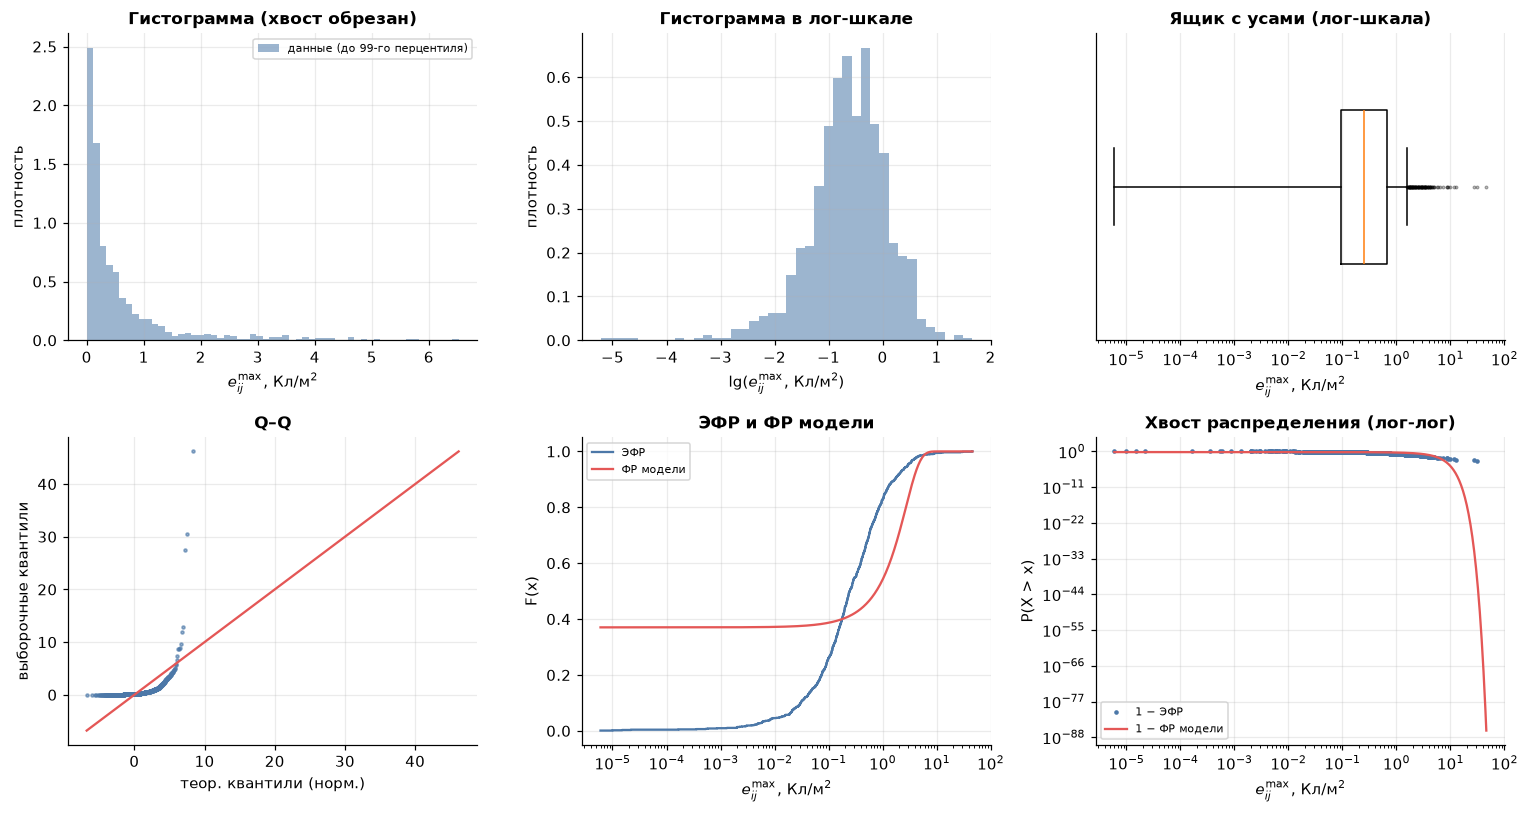

In [5]:
fig = S.eda_figure(x1, r'$e_{ij}^{\max}$, Кл/м$^2$'); plt.show()

**Масштабирование и преобразование формы.** Z-оценка и min–max меняют единицы и диапазон, но сохраняют асимметрию и эксцесс. Логарифм уменьшает влияние правого хвоста. Yeo–Johnson и квантильное преобразование подстраиваются под те же данные; значения теста нормальности после такой подстройки приведены как описательная диагностика, без обычной интерпретации уровня значимости. Квантильное преобразование приближает распределение к нормальному по построению и не подтверждает нормальность исходной величины.


In [6]:
nt1, _ = S.normalization_table(x1)
lg = np.log10(x1); z_lg = (lg - lg.mean()) / lg.std(ddof=1)
nt1.loc['lg x → z-оценка'] = [z_lg.mean(), z_lg.std(ddof=1), z_lg.min(), z_lg.max(), stats.skew(z_lg), stats.kurtosis(z_lg), stats.normaltest(z_lg).pvalue]
display(nt1)

,mean,std,min,max,skew,ex.kurt,p K² (после подгонки — описательно)
преобразование,,,,,,,
исходная,7.6290e-01,2.3064,6.0000e-06,46.1929,1.2698e+01,208.4368,0.0000e+00
z-score,0.0000e+00,1.0000,-3.3078e-01,19.6977,1.2698e+01,208.4368,0.0000e+00
min–max,1.6516e-02,0.0499,0.0000e+00,1.0000,1.2698e+01,208.4368,0.0000e+00
Yeo–Johnson,-2.1143e-16,1.0005,-1.4237e+00,2.0826,4.0793e-01,-1.0100,7.8961e-52
"квантиль→N(0,1)",1.0390e-13,1.0217,-5.1993e+00,5.1993,7.6138e-12,1.0211,3.6134e-05
lg x → z-оценка,-3.0204e-17,1.0000,-6.0612e+00,3.0466,-1.1489e+00,4.5761,1.7262e-53


**Сравнение моделей.** Параметры оцениваются методом максимального правдоподобия (MLE), положение фиксируется в нуле. Меньшие AIC и BIC предпочтительнее только среди рассмотренных кандидатов. КС-статистика показывает расхождение функций распределения; обычный p-value КС после оценки параметров по тем же данным некорректен, поэтому ниже применяется параметрический бутстреп с повторной подгонкой в каждой имитации.

Ломакс выбран для подробного разбора как простая двухпараметрическая модель тяжёлого хвоста. Его положение в сравнении с другими моделями видно в таблице. Бутстреп проверяет это семейство отдельно; перебор кандидатов в проверку не включён.


In [7]:
ft1 = S.fit_table(x1, ['lomax', 'genpareto', 'burr12', 'fisk', 'weibull_min', 'lognorm', 'gamma', 'invgauss', 'expon'], floc=0)
display(ft1.drop(columns='logL'))

,dist,k,AIC,BIC,KS D,params,ΔAIC
0,burr12,3,828.6492,843.1901,0.0233,"(0.8977, 2.1329, 0.0, 0.7725)",0.0000
1,lomax,2,832.4102,842.1041,0.0219,"(1.568, 0.0, 0.4734)",3.7610
2,genpareto,2,832.4102,842.1041,0.0219,"(0.6378, 0.0, 0.3019)",3.7610
3,fisk,2,854.6579,864.3518,0.0239,"(1.0896, 0.0, 0.2516)",26.0087
4,weibull_min,2,906.3357,916.0296,0.0564,"(0.6504, 0.0, 0.5112)",77.6864
5,lognorm,2,948.0622,957.7561,0.0640,"(1.7401, 0.0, 0.2296)",119.4130
6,gamma,2,1033.7318,1043.4257,0.1064,"(0.5251, 0.0, 1.453)",205.0825
7,expon,1,1374.6882,1379.5351,0.2271,"(0.0, 0.7629)",546.0389
8,invgauss,2,4231.9759,4241.6698,0.6901,"(329.7363, 0.0, 0.0023)",3403.3267


Lomax(α=1.568, λ=0.473):  KS D = 0.0219,  бутстреп-p = 0.249


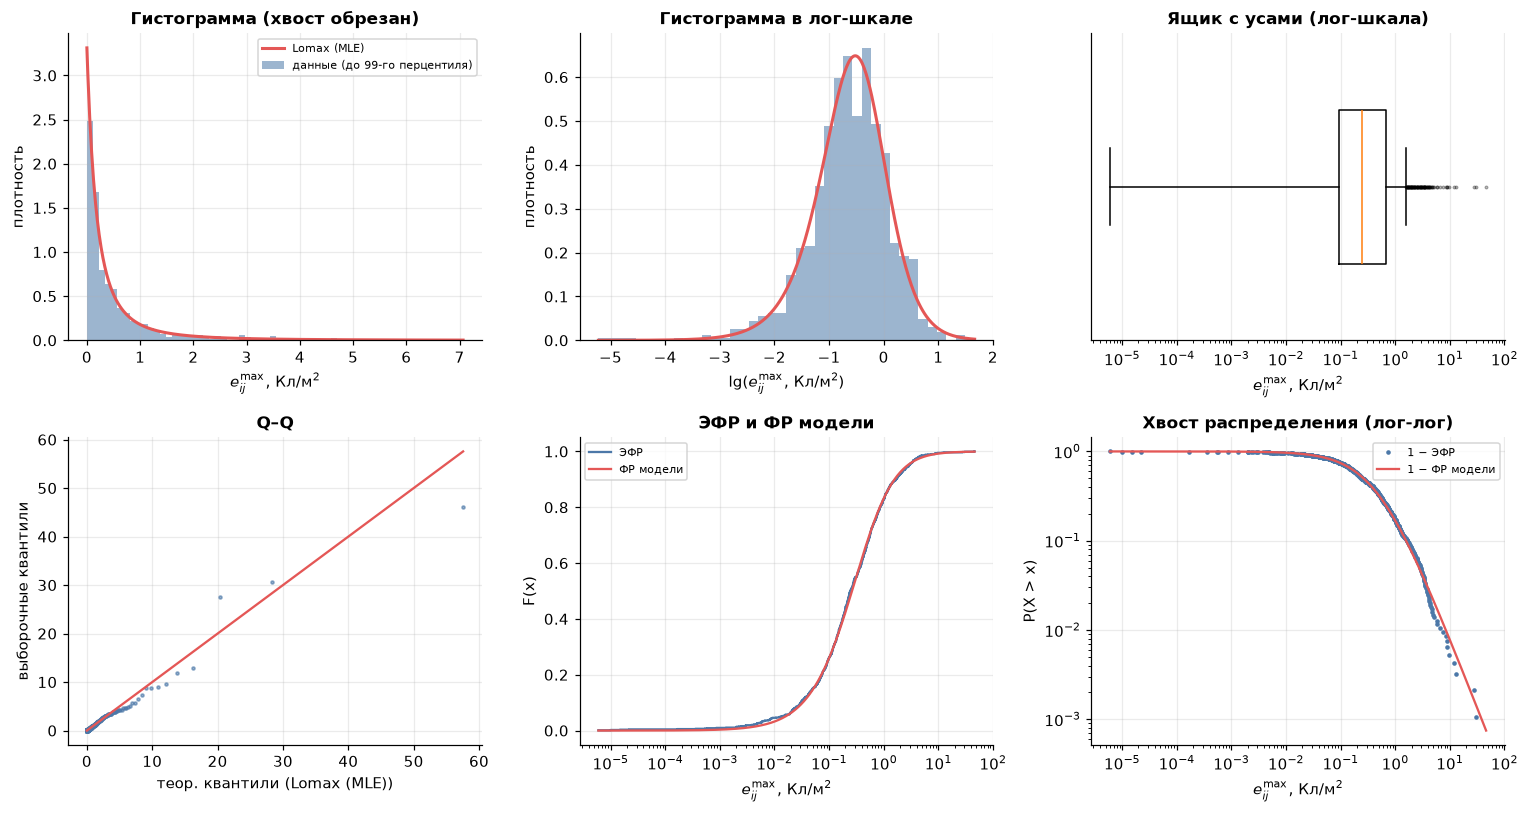

In [8]:
p1, D1, pb1 = S.param_bootstrap_ks(stats.lomax, x1, B=300, seed=SEED, floc=0)
print(f'Lomax(α={p1[0]:.3f}, λ={p1[2]:.3f}):  KS D = {D1:.4f},  бутстреп-p = {pb1:.3f}')
fig = S.eda_figure(x1, r'$e_{ij}^{\max}$, Кл/м$^2$', stats.lomax, p1, 'Lomax (MLE)'); plt.show()

#### Математическая модель: распределение Ломакса
Пусть $\alpha>0$ — параметр формы, $\lambda>0$ — масштаб. При $x\ge0$:
$$f(x)=\frac{\alpha}{\lambda}\left(1+\frac{x}{\lambda}\right)^{-\alpha-1},\qquad F(x)=1-\left(1+\frac{x}{\lambda}\right)^{-\alpha}$$
При больших $x$ функция выживания $1-F(x)\sim(\lambda/x)^\alpha$: хвост убывает по степенному закону. Это позволяет описать редкие большие отклики, однако не доказывает физического степенного закона за пределами наблюдаемого диапазона.

Момент порядка $k>0$ конечен при $k<\alpha$. В частности,
$$\mathbb EX=\frac{\lambda}{\alpha-1}\quad(\alpha>1),\qquad
\operatorname{Var}X=\frac{\lambda^2\alpha}{(\alpha-1)^2(\alpha-2)}\quad(\alpha>2)$$
Для полученной оценки $1<\hat\alpha<2$ модель имеет конечное среднее и бесконечную дисперсию. Это свойство идеализированного бесконечного распределения: у конечного набора из 941 записи дисперсия конечна. При независимых наблюдениях из точного закона Ломакса среднее всё равно состоятельно по закону больших чисел, но обычная ЦПТ с конечной дисперсией и стандартной ошибкой $\sigma/\sqrt m$ неприменима.

Для независимой выборки объёма $m$ логарифм правдоподобия равен
$$\ell=m\ln\alpha-m\ln\lambda-(\alpha+1)\sum_{i=1}^{m}\ln(1+x_i/\lambda)$$
При фиксированном $\lambda$ из $\partial\ell/\partial\alpha=0$ получаем
$$\hat\alpha(\lambda)=\frac{m}{\sum_i\ln(1+x_i/\lambda)}.$$
Вторая производная равна $-m/\alpha^2<0$. При совместной оценке масштаба требуется численная оптимизация, поскольку
$$\frac{\partial\ell}{\partial\lambda}=-\frac m\lambda+\frac{\alpha+1}{\lambda}\sum_i\frac{x_i}{\lambda+x_i}$$
На малых выборках совместная оценка формы и масштаба может быть неустойчива, особенно вблизи экспоненциальной границы семейства.

Ломакс — частный случай обобщённого распределения Парето: $\xi=1/\alpha$, $\beta=\lambda/\alpha$. Теорема Пикандса–Балкема–де Хаана объясняет приближение распределения превышений над высоким порогом семейством GPD при соответствующих условиях. Она не обосновывает автоматически закон Ломакса для всей выборки.

Обратная функция распределения имеет вид:
$$Q(u)=\lambda\big[(1-u)^{-1/\alpha}-1\big],\qquad 0<u<1$$
При равномерном $U$ на $(0,1)$ величина $Q(U)$ имеет распределение Ломакса


### Зависимость свойств и устойчивость оценок
Пьезокоэффициент и объём на атом относятся к одним и тем же структурам. Проверяем линейную и монотонную связь (Пирсон, Спирмен, Кендалл), а также зависимость категорий, полученных разбиением на квантили ($\chi^2$). Нулевая ранговая корреляция слабее независимости: отсутствие значимости не доказывает независимость. Отклонение независимости по этим данным не означает причинного влияния объёма.

Перестановки предполагают обменность строк. Общий состав и родственные структуры могут нарушать это допущение: p-value здесь следует считать исследовательскими, без переноса на все материалы.

Коэффициент Пирсона приводится как описательная линейная характеристика. Его стандартный p-value опирается на нормальные распределения; при выраженных тяжёлых хвостах он не используется как основание для основных выводов. Главные ранговые проверки дополнены перестановочной диагностикой.


,e_ij_max vs V/N
n,9.4100e+02
Pearson r,-1.2078e-01
"p (Pearson, норм. допущ.)",2.0427e-04
Spearman ρ,-4.2546e-01
p (Spearman),1.1675e-42
Kendall τ,-2.8862e-01
p (Kendall),4.1828e-40
χ² (3×3),1.4744e+02
p (χ²),7.1892e-31
Cramér V,2.7990e-01


col_0,0,1,2
row_0,,,
0,44,95,175
1,112,106,95
2,158,112,44


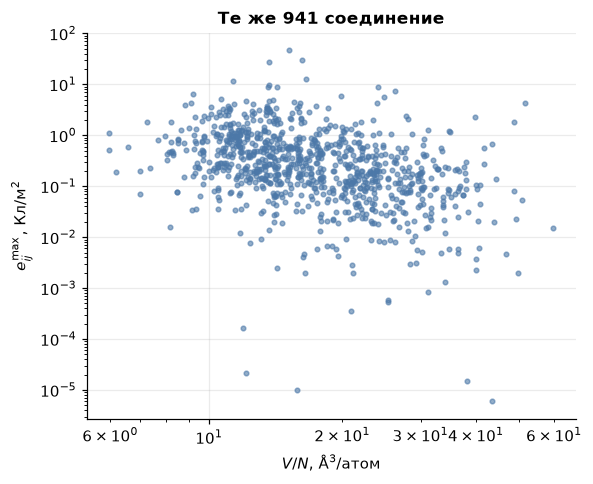

In [9]:
rep13, ct13 = S.independence_report(piezo.eij_max, piezo.vol_atom)
display(pd.Series(rep13, name='e_ij_max vs V/N').to_frame()); display(ct13)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.loglog(piezo.vol_atom, piezo.eij_max, '.', color=S.C['data'], alpha=.6)
ax.set(xlabel=r'$V/N$, Å$^3$/атом', ylabel=r'$e_{ij}^{\max}$, Кл/м$^2$', title='Те же 941 соединение'); plt.show()

**Состоятельность и имитационный эксперимент.** В этой части конечный датасет принимается за эмпирическую генеральную совокупность. Для каждого объёма $m$ многократно выбираем строки без возвращения. Уменьшение разброса при приближении $m$ к $N$ показывает точность восстановления характеристик этого набора, но не доказывает асимптотическую состоятельность для всех материалов.

Для i.i.d. выборки из распределения с конечными необходимыми моментами среднее и исправленная дисперсия состоятельны; медиана состоятельна при единственности и регулярности популяционной медианы. Контрпример $X_1$ использует только первое наблюдение: его распределение не меняется с объёмом выборки, поэтому ошибка в общем случае не стремится к нулю.

В таблицах $\varepsilon=0.1|\theta|$ задаётся отдельно для каждой характеристики: это 10% от её значения на полном наборе. Ошибки дисперсии и безразмерного параметра нельзя сравнивать с порогом в единицах исходной величины.


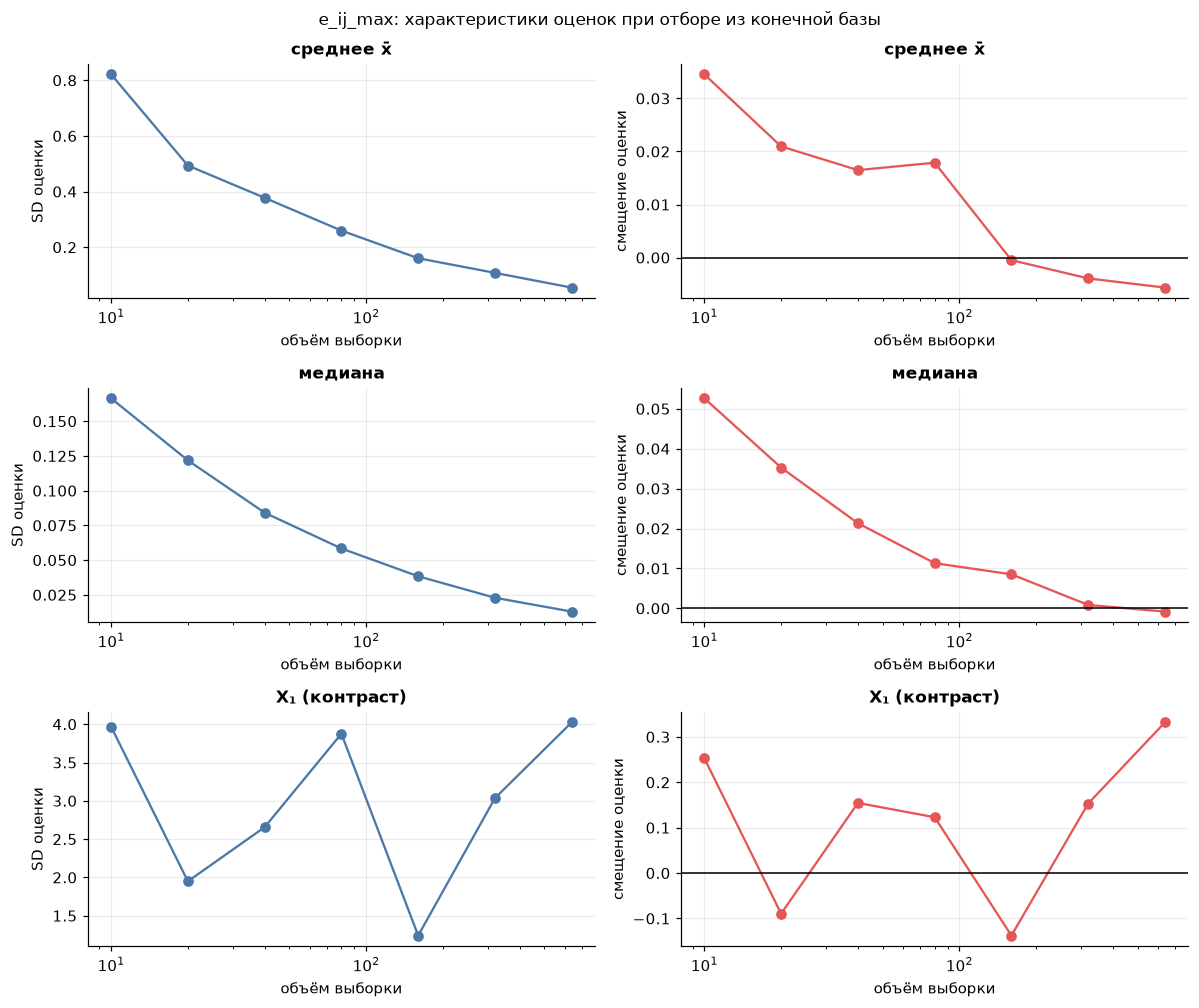

"P(|θ̂−θ| > ε), ε = 0.1|θ|",X₁ (контраст),медиана,среднее x̄
n,,,
10,0.9533,0.8600,0.9067
20,0.9533,0.7833,0.8067
40,0.9500,0.7467,0.8067
80,0.9433,0.6533,0.7500
160,0.9767,0.5000,0.6467
320,0.9667,0.3333,0.5333
640,0.9567,0.0467,0.1767


In [10]:
ns = [10, 20, 40, 80, 160, 320, 640]
est1 = {'среднее x̄': (np.mean, None), 'медиана': (np.median, None), 'X₁ (контраст)': (lambda s: s[0], np.mean)}
tab1 = S.consistency_curve(x1, est1, ns, reps=300, seed=SEED)
fig = S.consistency_figure(tab1, list(est1), 'e_ij_max'); plt.show()
display(tab1.pivot(index='n', columns='estimator', values='P(|err|>eps)').rename_axis(columns='P(|θ̂−θ| > ε), ε = 0.1|θ|'))

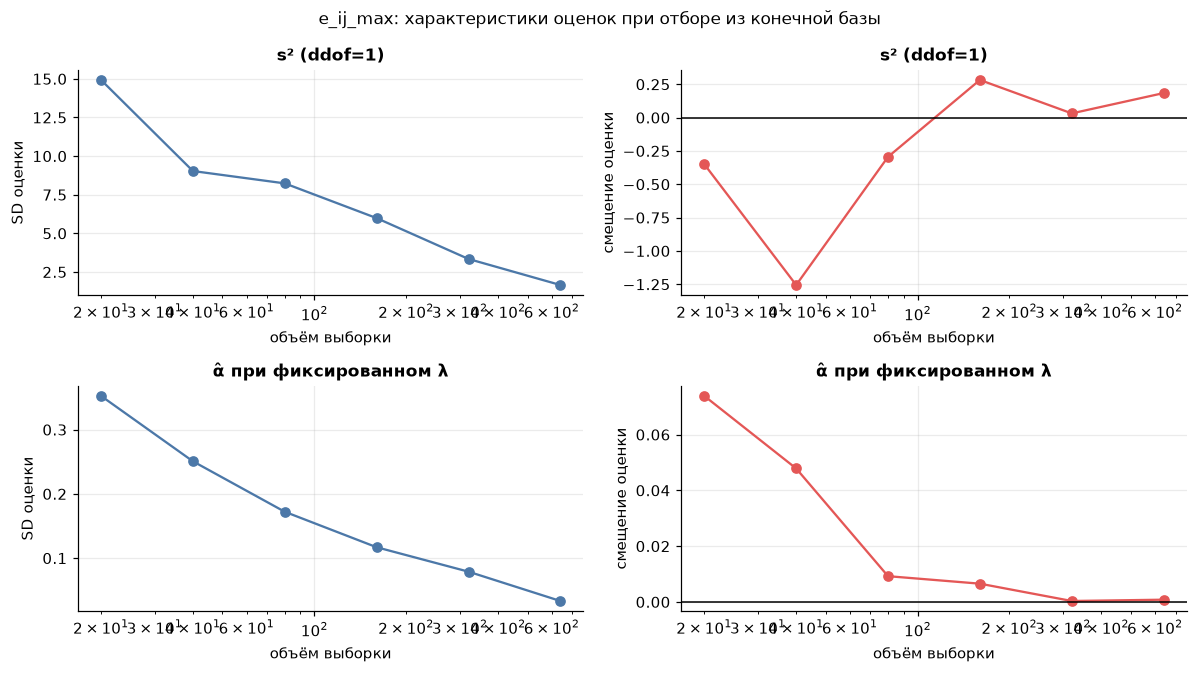

,n,estimator,truth,eps,mean_est,bias,sd
0,20,s² (ddof=1),5.3193,0.5319,4.9697,-0.3496,14.9280
1,20,α̂ при фиксированном λ,1.5680,0.1568,1.6418,0.0739,0.3525
2,40,s² (ddof=1),5.3193,0.5319,4.0636,-1.2557,9.0339
3,40,α̂ при фиксированном λ,1.5680,0.1568,1.6158,0.0479,0.2507
4,80,s² (ddof=1),5.3193,0.5319,5.0249,-0.2944,8.2353
5,80,α̂ при фиксированном λ,1.5680,0.1568,1.5772,0.0092,0.1722
6,160,s² (ddof=1),5.3193,0.5319,5.6017,0.2824,5.9860
7,160,α̂ при фиксированном λ,1.5680,0.1568,1.5745,0.0065,0.1170
8,320,s² (ddof=1),5.3193,0.5319,5.3509,0.0317,3.3423
9,320,α̂ при фиксированном λ,1.5680,0.1568,1.5683,0.0003,0.0789


In [11]:
fixed_scale = p1[2]
alpha_fixed = lambda s: len(s) / np.log1p(s / fixed_scale).sum()
est1b = {'s² (ddof=1)': (lambda s: s.var(ddof=1), None),
         'α̂ при фиксированном λ': (alpha_fixed, None)}
tab1b = S.consistency_curve(x1, est1b, [20, 40, 80, 160, 320, 640], reps=200, seed=SEED + 1)
fig = S.consistency_figure(tab1b, list(est1b), 'e_ij_max'); plt.show()
display(tab1b[['n', 'estimator', 'truth', 'eps', 'mean_est', 'bias', 'sd']])

### Выборка с возвращением и без возвращения
Пусть $N$ — число строк, $\sigma_N^2=N^{-1}\sum_i(x_i-\mu_N)^2$ и $S_N^2=(N-1)^{-1}\sum_i(x_i-\mu_N)^2$. Для выборки объёма $m$:
$$\mathrm{SE}(\bar X)=\frac{\sigma_N}{\sqrt m}\quad\text{с возвращением},\qquad
\mathrm{SE}(\bar X)=\frac{S_N}{\sqrt m}\sqrt{1-\frac mN}\quad\text{без возвращения}.$$
Исправленная выборочная дисперсия несмещённо оценивает $\sigma_N^2$ в первом случае и $S_N^2$ во втором. Формулы точны для случайного отбора из конечного набора и не требуют нормальности. Сильный хвост увеличивает нестабильность имитационных оценок на малых выборках.

Для одной выбранной подвыборки приводится только расстояние КС до полного набора. Двухвыборочный p-value не используется: подвыборка и полный набор зависимы.


In [12]:
rows = [S.sampling_experiment(x1, n, reps=4000, replace=r, seed=SEED) for n in (30, 100, 300) for r in (True, False)]
display(pd.DataFrame(rows))
pop1 = pd.Series({'N': len(x1), 'μ': x1.mean(), 'σ (N)': x1.std(ddof=0), 'S (N−1)': x1.std(ddof=1), 'медиана': np.median(x1), 'skew': stats.skew(x1), 'ex.kurt': stats.kurtosis(x1)}, name='генеральная')
display(pop1.to_frame().T); display(pd.DataFrame([S.one_sample_report(x1, n, r) for n in (30, 100, 300) for r in (True, False)]))

,n,replace,E[x̄],SE(x̄) эмпир.,SE(x̄) теор.,E[s²],σ² (N),S² (N−1),SE(median)
0,30,True,0.7568,0.4070,0.4209,5.0128,5.3136,5.3193,0.0980
1,30,False,0.7612,0.4222,0.4143,5.2194,5.3136,5.3193,0.0950
2,100,True,0.7584,0.2246,0.2305,5.1214,5.3136,5.3193,0.0541
3,100,False,0.7609,0.2162,0.2180,5.2407,5.3136,5.3193,0.0498
4,300,True,0.7615,0.1328,0.1331,5.2948,5.3136,5.3193,0.0294
5,300,False,0.7620,0.1076,0.1099,5.2763,5.3136,5.3193,0.0242


,N,μ,σ (N),S (N−1),медиана,skew,ex.kurt
генеральная,941.0,0.7629,2.3051,2.3064,0.2477,12.6978,208.4368


,n,replace,mean,std,median,skew,kurt,KS D (описательно)
0,30,True,0.3701,0.4762,0.1743,2.0893,4.8538,0.1434
1,30,False,1.8968,5.3125,0.2651,4.0377,16.3456,0.0972
2,100,True,0.6006,1.3706,0.2132,5.1066,28.7164,0.1230
3,100,False,0.7241,1.2803,0.2757,3.8704,18.1626,0.1027
4,300,True,1.0581,3.7040,0.2907,9.1099,93.4878,0.0659
5,300,False,0.7595,2.0377,0.2722,11.0545,152.1879,0.0367


### Проверка гипотез
Уровень значимости — 0.05. В каждой строке указаны гипотезы, критерий и эффект. Итоговая таблица дополнительно содержит поправку Холма для всех уникальных проверок двух разделов.

Манн–Уитни сравнивает распределения/ранговое превосходство; без допущения об одинаковой форме распределений это не просто тест равенства медиан. $\delta$ Клиффа описывает направление и величину эффекта. Односторонние альтернативы считаются исходными исследовательскими предположениями; менять сторону после просмотра результата нельзя. Непринятие альтернативы не означает доказанности $H_0$.


In [13]:
H = []
def add(h, h0, h1, test, stat, p, eff, alpha=0.05):
    H.append({'гипотеза': h, 'H0': h0, 'H1': h1, 'критерий': test, 'статистика': stat, 'p': p, 'эффект': eff,
              'решение': 'H0 отвергается' if p < alpha else 'H0 не отвергается'})
def mwu(a, b, alt):
    m = stats.mannwhitneyu(a, b, alternative=alt); return m.statistic, m.pvalue, 2 * m.statistic / (len(a) * len(b)) - 1
lgx = np.log10(x1)
k2 = stats.normaltest(lgx)
add('H1.1', 'lg e_ij_max ~ N(μ,σ²)', 'не нормален', 'D’Agostino K²', k2.statistic, k2.pvalue, f'skew={stats.skew(lgx):.2f}')
add('H1.2', 'e_ij_max ~ Lomax(α, λ)', 'иное распределение', 'КС, парам. бутстреп', D1, pb1, f'α̂={p1[0]:.2f}')
st, p, cl = mwu(piezo.eij_max[piezo.toxic], piezo.eij_max[~piezo.toxic], 'greater')
add('H1.3', 'e_ij_max (с токсичными эл-тами) = (без них)', 'у токсичных больше', 'Манн–Уитни (одностор.)', st, p, f'δ Клиффа={cl:.2f}; медианы {piezo.eij_max[piezo.toxic].median():.2f}/{piezo.eij_max[~piezo.toxic].median():.2f}')
st, p, cl = mwu(piezo.eij_max[piezo.polar], piezo.eij_max[~piezo.polar], 'two-sided')
add('H1.4', 'e_ij_max (полярные группы) = (неполярные)', '≠', 'Манн–Уитни', st, p, f'δ Клиффа={cl:.2f}')
st, p, cl = mwu(piezo.eij_max[piezo.has_O], piezo.eij_max[~piezo.has_O], 'two-sided')
add('H1.5', 'e_ij_max (оксиды) = (не оксиды)', '≠', 'Манн–Уитни', st, p, f'δ Клиффа={cl:.2f}')
add('H1.6', 'ρ Спирмена(e_ij_max, V/N) = 0', 'ρ ≠ 0', 'Спирмен', rep13['Spearman ρ'], rep13['p (Spearman)'], f'ρ={rep13["Spearman ρ"]:.2f}')
H1 = pd.DataFrame(H); display(H1)

,гипотеза,H0,H1,критерий,статистика,p,эффект,решение
0,H1.1,"lg e_ij_max ~ N(μ,σ²)",не нормален,D’Agostino K²,242.9822,1.7262e-53,skew=-1.15,H0 отвергается
1,H1.2,"e_ij_max ~ Lomax(α, λ)",иное распределение,"КС, парам. бутстреп",0.0219,2.4917e-01,α̂=1.57,H0 не отвергается
2,H1.3,e_ij_max (с токсичными эл-тами) = (без них),у токсичных больше,Манн–Уитни (одностор.),46635.0000,9.9964e-01,δ Клиффа=-0.18; медианы 0.16/0.27,H0 не отвергается
3,H1.4,e_ij_max (полярные группы) = (неполярные),≠,Манн–Уитни,174981.0000,1.0253e-56,δ Клиффа=0.60,H0 отвергается
4,H1.5,e_ij_max (оксиды) = (не оксиды),≠,Манн–Уитни,163058.0000,2.7281e-36,δ Клиффа=0.47,H0 отвергается
5,H1.6,"ρ Спирмена(e_ij_max, V/N) = 0",ρ ≠ 0,Спирмен,-0.4255,1.1675e-42,ρ=-0.43,H0 отвергается


### Выводы по пьезокоэффициенту

**Асимметрия данных:** Распределение сильно смещено вправо (среднее ~0.763, медиана — 0.248, максимум — 46.2 Кл/м²). Из-за редких «выбросов» среднее искажается, поэтому для типичной картины лучше смотреть на медиану и межквартильный размах. Экстремальные значения не удаляли, несмотря на их величину.

**Форма распределения:** Ломакс компактно описывает «тяжелый хвост» данных, хотя по AIC выигрывает Burr XII. Бутстреп-тест не выявил явных противоречий с Ломаксом, но и не доказал его абсолютную верность. При этом бесконечная дисперсия, которую предсказывает закон, — это свойство модели, а не реальной базы или физики явления.

**Влияние структуры:** Связь с объемом на атом отрицательная ($\rho \approx -0.43$): чем больше объем, тем меньше отклик. Влияние полярности и наличия кислорода в базе заметно, но эти факторы перемешаны с составом и структурой, поэтому выделить их чистый эффект не получается.

**Гипотеза о токсичности:** Предположение, что материалы с потенциально токсичными элементами дают больший отклик, не подтвердилось (медианы 0.16 и 0.27 Кл/м²). Это значит, что сильные пьезоэффекты можно искать и без таких элементов, но их безопасность или технологичность это не гарантирует.

**Размер выборки:** С ростом объема данных оценки становятся стабильнее. Дисперсия особенно чувствительна к «хвосту». $X_1$ — наглядный контрпример: он не использует новые наблюдения, а фиксированный масштаб в этом эксперименте — не то же самое, что совместная оценка всех параметров на новых данных.

<a id="rv2"></a>
## Величина 2 — $n$ (показатель преломления)


### Что измеряется и откуда возникает случайность
Показатель преломления $n$ — безразмерное целевое свойство Matbench `matbench_dielectric`, рассчитанное для неорганических кристаллов. В прозрачной немагнитной среде он связан с электронной диэлектрической проницаемостью; для анизотропного кристалла скаляризация тензора зависит от соглашения источника. В расчётах используется табличное скалярное значение; тензор по нему не восстанавливается.

Случайный эксперимент — выбрать запись из этого набора. Расчёт фиксированного кристалла детерминирован; ошибки модели отражают неполноту её описания. Значения $n\ge1$ характерны для переданной таблицы и рассматриваемого режима; это не универсальное ограничение показателя преломления на всех частотах.

В таблице нет ширины запрещённой зоны. Поэтому связь 27 больших значений $n>10$ с малой щелью по этим файлам не проверяется и не используется как установленное объяснение. Крупные значения сохраняются в анализе, поскольку одних статистических оснований недостаточно, чтобы считать их ошибками.


,N,R² (MODNet),MAE,"Спирмен(n, предсказание)"
fold,,,,
0,953.0,0.6485,0.1691,0.9684
1,953.0,0.4894,0.2410,0.9516
2,953.0,0.1153,0.3899,0.9318
3,953.0,0.1633,0.2775,0.9700
4,952.0,0.2092,0.2781,0.9321


по всем данным: R² = 0.205, MAE = 0.271, Спирмен = 0.950


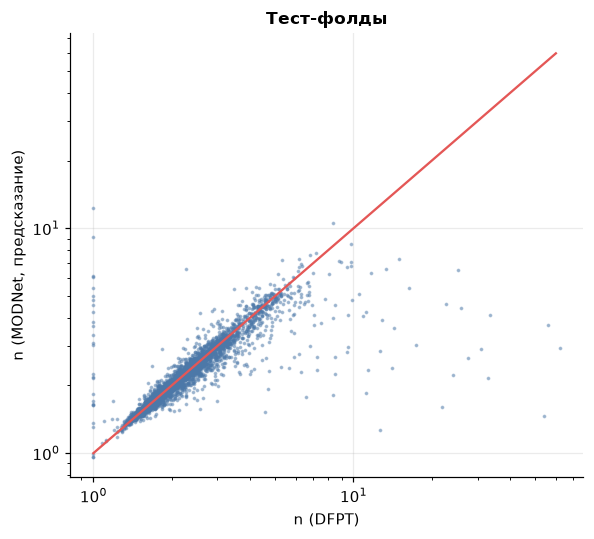

In [14]:
r2 = lambda d: 1 - ((d.n - d.n_pred_modnet) ** 2).sum() / ((d.n - d.n.mean()) ** 2).sum()
folds = diel.groupby('fold')[['n', 'n_pred_modnet']].apply(lambda d: pd.Series({'N': len(d), 'R² (MODNet)': r2(d), 'MAE': (d.n - d.n_pred_modnet).abs().mean(),
                                                       'Спирмен(n, предсказание)': stats.spearmanr(d.n, d.n_pred_modnet)[0]}))
display(folds); print(f'по всем данным: R² = {r2(diel):.3f}, MAE = {(diel.n - diel.n_pred_modnet).abs().mean():.3f}, Спирмен = {stats.spearmanr(diel.n, diel.n_pred_modnet)[0]:.3f}')
fig, ax = plt.subplots(figsize=(5.5, 5)); ax.loglog(diel.n, diel.n_pred_modnet, '.', ms=3, alpha=.4, color=S.C['data']); ax.plot([1, 60], [1, 60], color=S.C['fit'])
ax.set(xlabel='n (DFPT)', ylabel='n (MODNet, предсказание)', title='Тест-фолды'); plt.show()

Сохранённые предсказания MODNet хорошо сохраняют ранжирование объектов (Спирмен около 0.95), но агрегированное $R^2$ составляет около 0.21 при MAE около 0.27. Эти метрики описывают разные стороны качества: квадратичная ошибка особенно чувствительна к нескольким большим значениям. На точность влияет состав тестовой выборки, особенно редкие большие значения $n$.


### Описательная статистика и распределение


,n
n,4764.0000
mean,2.4283
std (ddof=1),2.1017
min,1.0000
Q1,1.6846
median,2.0608
Q3,2.5953
max,62.0630
IQR,0.9107
skew,15.3551


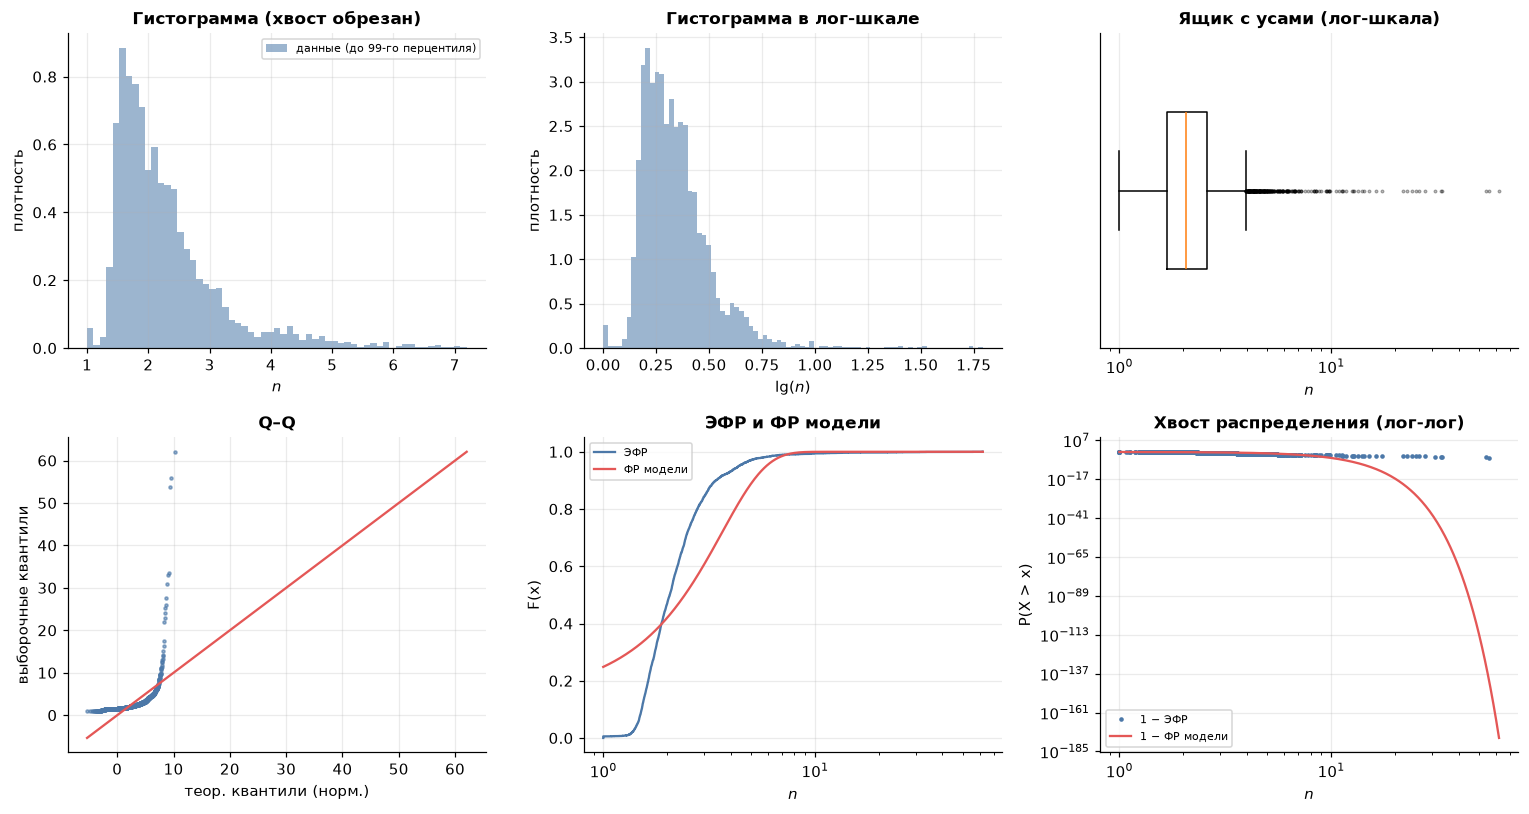

In [15]:
display(S.summary(x2).to_frame('n'))
fig = S.eda_figure(x2, r'$n$'); plt.show()

In [16]:
nt2, _ = S.normalization_table(x2)
lg = np.log10(x2); z_lg = (lg - lg.mean()) / lg.std(ddof=1)
nt2.loc['lg x → z-оценка'] = [z_lg.mean(), z_lg.std(ddof=1), z_lg.min(), z_lg.max(), stats.skew(z_lg), stats.kurtosis(z_lg), stats.normaltest(z_lg).pvalue]
display(nt2)
ft2 = S.fit_table(x2, ['genextreme', 'johnsonsu', 'burr12', 'fisk', 'lognorm', 'invgauss', 'skewnorm', 'norm', 'gamma'])
display(ft2.drop(columns='logL'))

,mean,std,min,max,skew,ex.kurt,p K² (после подгонки — описательно)
преобразование,,,,,,,
исходная,2.4283e+00,2.1017,1.0000,62.0630,15.3551,341.8513,0.0000e+00
z-score,-5.8168e-17,1.0000,-0.6796,28.3742,15.3551,341.8513,0.0000e+00
min–max,2.3391e-02,0.0344,0.0000,1.0000,15.3551,341.8513,0.0000e+00
Yeo–Johnson,-3.8913e-15,1.0001,-3.3515,2.6774,0.0828,-0.0912,2.8394e-02
"квантиль→N(0,1)",-1.2915e-02,1.0539,-5.1993,5.1993,-0.5101,2.5404,1.3860e-103
lg x → z-оценка,9.0235e-17,1.0000,-2.0958,8.8965,1.9752,8.7864,0.0000e+00


,dist,k,AIC,BIC,KS D,params,ΔAIC
0,johnsonsu,4,10050.2673,10076.1427,0.0318,"(-1.721, 1.005, 1.4246, 0.2203)",0.0000
1,burr12,4,10073.9234,10099.7988,0.0316,"(24.9777, 0.1498, -0.922, 2.4407)",23.6561
2,genextreme,3,10240.5496,10259.9561,0.0300,"(-0.2807, 1.8716, 0.5126)",190.2823
3,fisk,3,10295.9327,10315.3392,0.0412,"(2.9169, 0.9381, 1.1314)",245.6654
4,lognorm,3,10647.9129,10667.3194,0.0521,"(0.6062, 0.8886, 1.2197)",597.6455
5,invgauss,3,11041.2295,11060.6360,0.0716,"(0.4524, 0.8396, 3.5117)",990.9622
6,gamma,3,13530.0302,13549.4367,0.2051,"(0.8927, 1.0, 2.2243)",3479.7629
7,skewnorm,3,15608.6445,15628.0510,0.3220,"(17.9144, 1.2209, 2.4237)",5558.3772
8,norm,2,20599.6358,20612.5735,0.2889,"(2.4283, 2.1015)",10549.3685


GEV: c=-0.281 (ξ=−c=0.281), μ=1.872, σ=0.513;  KS D = 0.0300, бутстреп-p = 0.003


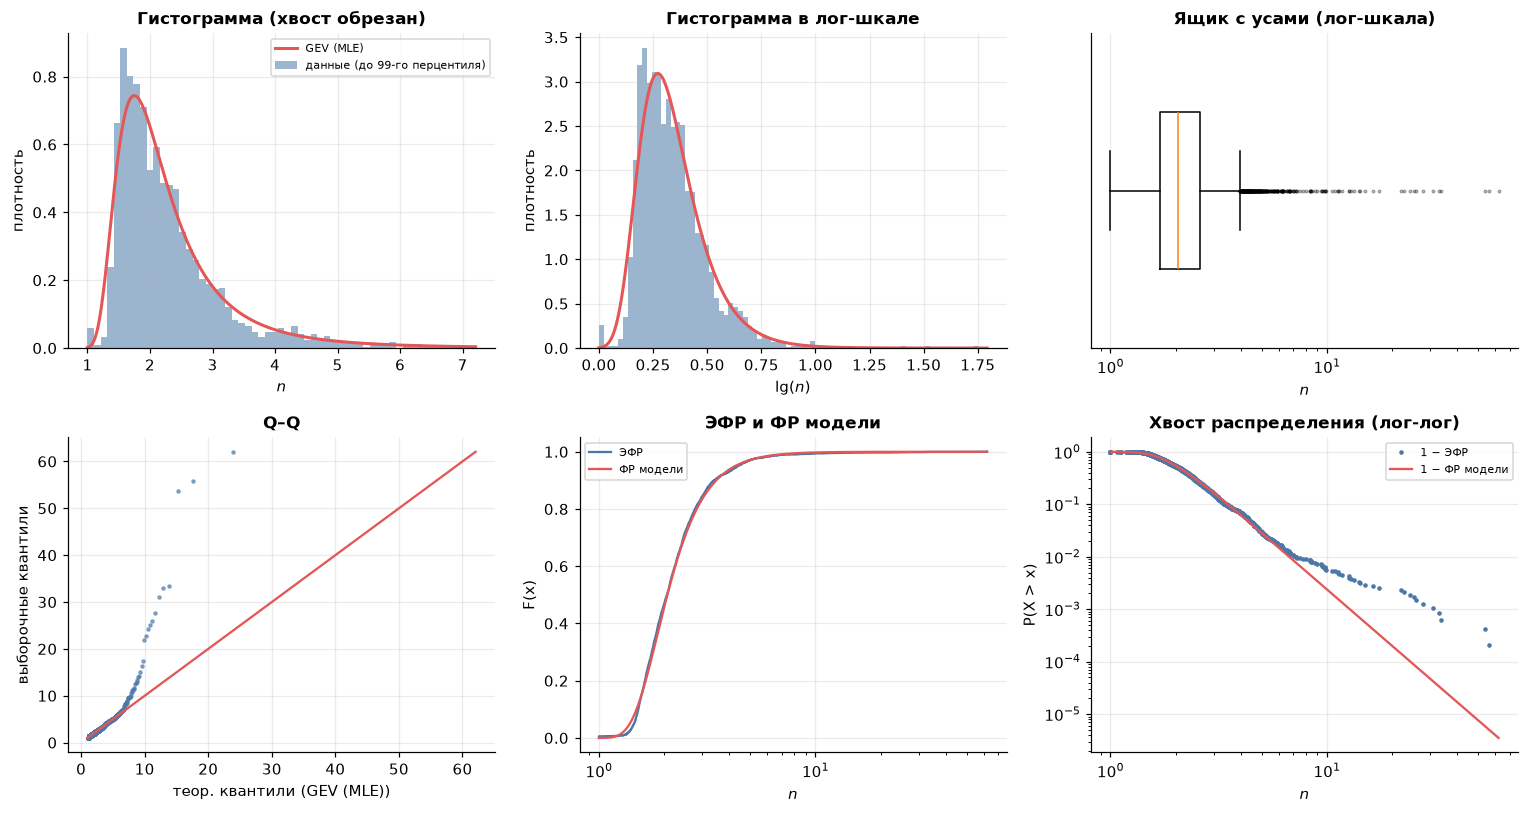

In [17]:
p2, D2, pb2 = S.param_bootstrap_ks(stats.genextreme, x2, B=299, seed=SEED)
print(f'GEV: c={p2[0]:.3f} (ξ=−c={-p2[0]:.3f}), μ={p2[1]:.3f}, σ={p2[2]:.3f};  KS D = {D2:.4f}, бутстреп-p = {pb2:.3f}')
fig = S.eda_figure(x2, r'$n$', stats.genextreme, p2, 'GEV (MLE)'); plt.show()

#### Математическая база: обобщённое распределение экстремальных значений (GEV)
Параметры $\mu$, $\sigma>0$, $\xi\in\mathbb R$ (в `scipy`: $c=-\xi$). При $\xi\ne0$:
$$F(x)=\exp\Big\{-\Big[1+\xi\frac{x-\mu}\sigma\Big]^{-1/\xi}\Big\},\quad 1+\xi\frac{x-\mu}\sigma>0,\qquad Q(u)=\mu+\frac\sigma\xi\big[(-\ln u)^{-\xi}-1\big]$$
При $\xi>0$ — тип Фреше (тяжёлый хвост, нижняя граница $\mu-\sigma/\xi$), $\xi=0$ — Гумбель, $\xi<0$ — Вейбулл (верхняя граница). Момент порядка $k$ конечен при $\xi<1/k$

Плотность получается дифференцированием функции распределения. Для $t=1+\xi(x-\mu)/\sigma>0$:
$$f(x)=\frac1\sigma t^{-1/\xi-1}\exp(-t^{-1/\xi})$$
В пределе $\xi\to0$ имеем $F(x)=\exp[-\exp(-(x-\mu)/\sigma)]$

Теорема Фишера–Типпета–Гнеденко описывает возможные невырожденные пределы нормированных максимумов i.i.d. выборок при соответствующих условиях. Набор значений $n$ не является выборкой блоковых максимумов: теорема сама по себе не объясняет появление GEV здесь. Это гибкий кандидат для сравнения формы, а не установленная физическая модель.

При оценке $\hat\xi\approx0.28$ получается тип Фреше: среднее, дисперсия и третий момент конечны, четвёртый момент расходится. Нижняя граница модели около 0.046, так что она допускает значения $n<1$, которых в исходной таблице нет. При генерации значений это ограничение нужно учитывать.

По AIC среди проверенных семейств лучше Johnson SU, а GEV имеет заметно больший AIC. Параметрический бутстреп КС для GEV даёт основание отклонить это семейство на уровне 0.05. Преимущество Johnson SU по AIC — относительное: его абсолютное согласие отдельно не проверялось, а носитель также выходит за наблюдаемую область.

Квантиль $Q(u)$ позволяет строить генератор GEV методом обратной функции, но такой генератор воспроизводил бы выбранную модель со всеми её ограничениями. Применение такого генератора потребует подходящей модели данных.

Оценивание параметров GEV также выполняется MLE. При $t_i=1+\xi(x_i-\mu)/\sigma>0$ и $\xi\ne0$:
$$\ell(\mu,\sigma,\xi)=-m\ln\sigma-\left(1+\frac1\xi\right)\sum_i\ln t_i-\sum_i t_i^{-1/\xi}$$
Максимум ищется численно при ограничениях $\sigma>0$ и $t_i>0$. Если эти условия нарушаются, параметрическая точка недопустима. При $\xi=0$ используется предельная форма Гумбеля. Для $\xi<1$ среднее равно $\mu+\sigma[\Gamma(1-\xi)-1]/\xi$; при $\xi<1/2$ дисперсия равна $\sigma^2[\Gamma(1-2\xi)-\Gamma^2(1-\xi)]/\xi^2$ (для $\xi=0$ берутся пределы).


### Связь ошибки модели со значением свойства
Попарной таблицы $n$ и пьезокоэффициента одного материала нет, поэтому их зависимость остаётся неизвестной. Независимый выбор строки из каждого файла создал бы независимую пару по процедуре выборки, но ничего не сказал бы о физических свойствах одного кристалла.

Внутри второго датасета сравниваем $n$ с абсолютной ошибкой MODNet. Ошибка вычисляется с участием самого $n$, так что выявленная связь не является независимым физическим эффектом. Она показывает, в какой части диапазона текущие предсказания менее точны.

Эксперимент с подвыборками проводится по тем же правилам и с теми же ограничениями, что и в первом разделе. Параметр масштаба GEV здесь — характеристика численной подгонки к эмпирическому набору; уменьшение её разброса не делает отвергнутое семейство верным.


In [18]:
err = (diel.n - diel.n_pred_modnet).abs()
rep2, ct2 = S.independence_report(diel.n, err)
display(pd.Series(rep2, name='n vs |ошибка MODNet|').to_frame())

,n vs |ошибка MODNet|
n,4.7640e+03
Pearson r,9.1300e-01
"p (Pearson, норм. допущ.)",0.0000e+00
Spearman ρ,5.3792e-01
p (Spearman),0.0000e+00
Kendall τ,3.8388e-01
p (Kendall),0.0000e+00
χ² (3×3),1.1219e+03
p (χ²),1.3495e-241
Cramér V,3.4315e-01


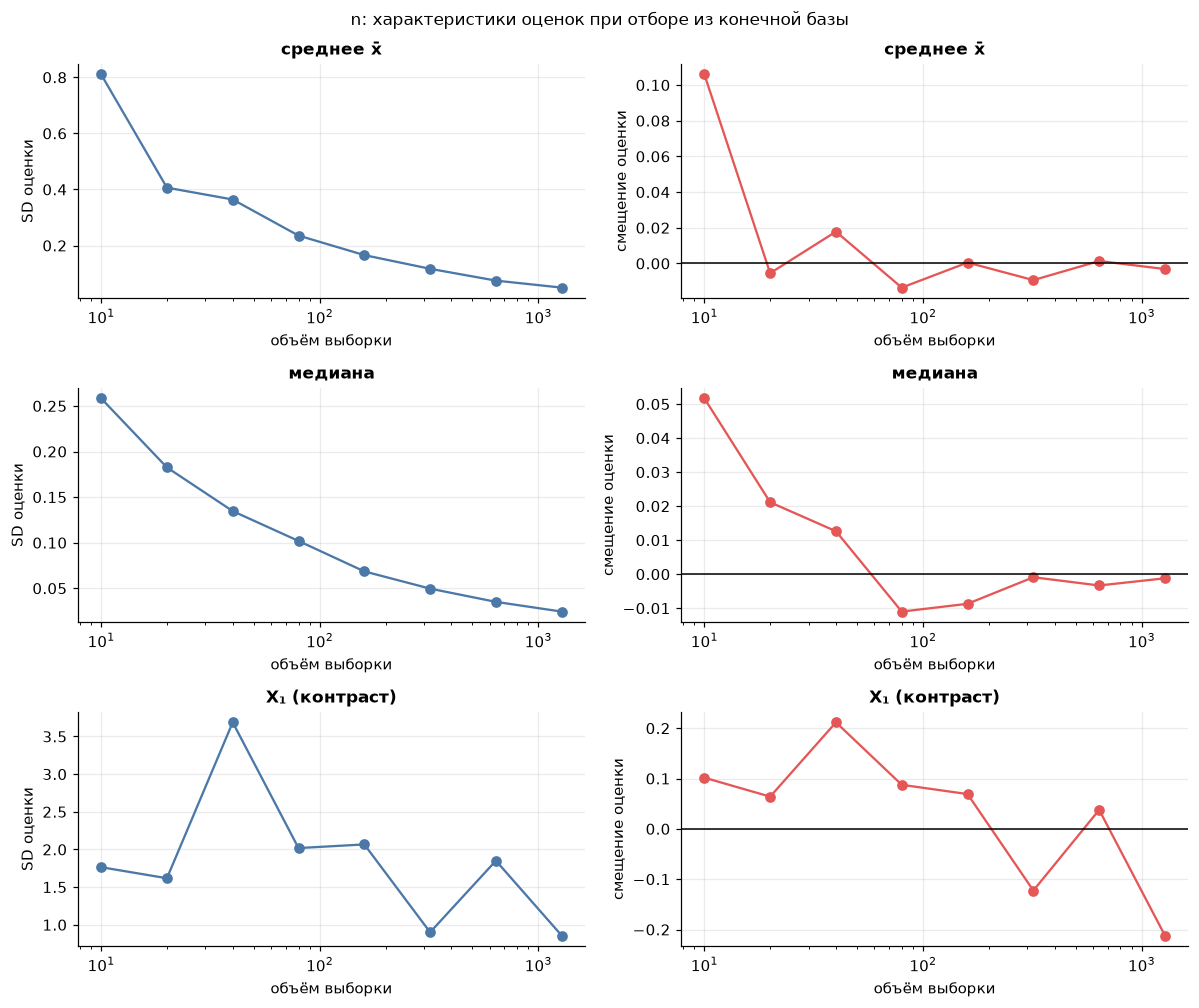

"P(|θ̂−θ| > ε), ε = 0.1|θ|",X₁ (контраст),медиана,среднее x̄
n,,,
10,0.8333,0.3900,0.5333
20,0.7633,0.2733,0.4100
40,0.7700,0.1333,0.3667
80,0.7967,0.0433,0.2200
160,0.7833,0.0033,0.1167
320,0.8233,0.0000,0.0400
640,0.7667,0.0000,0.0033
1280,0.8467,0.0000,0.0000


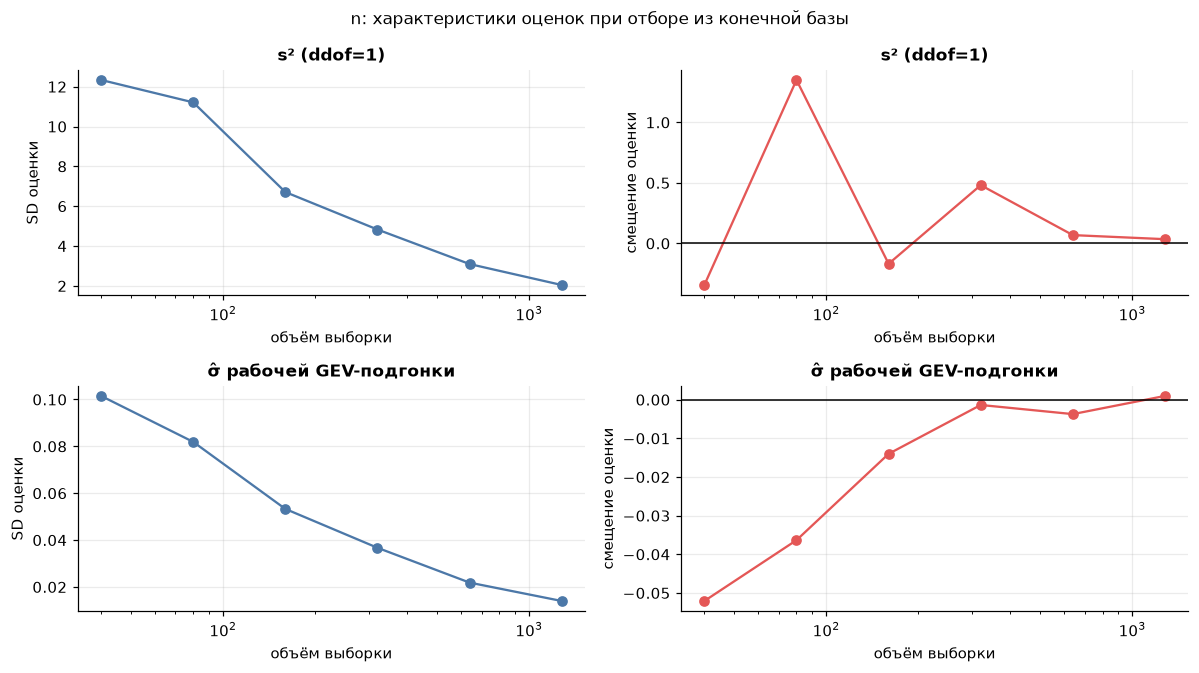

,n,estimator,truth,mean_est,bias,sd
0,40,s² (ddof=1),4.4172,4.0735,-0.3438,12.3369
1,40,σ̂ рабочей GEV-подгонки,0.5126,0.4605,-0.0521,0.1015
2,80,s² (ddof=1),4.4172,5.7677,1.3504,11.2116
3,80,σ̂ рабочей GEV-подгонки,0.5126,0.4763,-0.0363,0.0819
4,160,s² (ddof=1),4.4172,4.2488,-0.1684,6.7090
5,160,σ̂ рабочей GEV-подгонки,0.5126,0.4986,-0.0140,0.0533
6,320,s² (ddof=1),4.4172,4.8985,0.4812,4.8283
7,320,σ̂ рабочей GEV-подгонки,0.5126,0.5112,-0.0014,0.0367
8,640,s² (ddof=1),4.4172,4.4857,0.0685,3.0957
9,640,σ̂ рабочей GEV-подгонки,0.5126,0.5089,-0.0037,0.0219


In [19]:
ns = [10, 20, 40, 80, 160, 320, 640, 1280]
est2 = {'среднее x̄': (np.mean, None), 'медиана': (np.median, None), 'X₁ (контраст)': (lambda s: s[0], np.mean)}
tab2 = S.consistency_curve(x2, est2, ns, reps=300, seed=SEED)
fig = S.consistency_figure(tab2, list(est2), 'n'); plt.show()
display(tab2.pivot(index='n', columns='estimator', values='P(|err|>eps)').rename_axis(columns='P(|θ̂−θ| > ε), ε = 0.1|θ|'))
est2b = {'s² (ddof=1)': (lambda s: s.var(ddof=1), None), 'σ̂ рабочей GEV-подгонки': (lambda s: stats.genextreme.fit(s)[2], None)}
tab2b = S.consistency_curve(x2, est2b, [40, 80, 160, 320, 640, 1280], reps=60, seed=SEED)
fig = S.consistency_figure(tab2b, list(est2b), 'n'); plt.show()
display(tab2b[['n', 'estimator', 'truth', 'mean_est', 'bias', 'sd']])

### Выборка с возвращением и без возвращения
Сравниваем эмпирическую стандартную ошибку среднего с формулами для конечной совокупности из первого раздела. При большой доле отбора поправка $\sqrt{1-m/N}$ заметно уменьшает разброс среднего. Нормальность наблюдений для этого результата не требуется. Отдельные выборки могут плохо воспроизводить хвост из-за редкости крупных значений.


In [20]:
rows = [S.sampling_experiment(x2, n, reps=4000, replace=r, seed=SEED) for n in (30, 300, 1500) for r in (True, False)]
display(pd.DataFrame(rows))
pop2 = pd.Series({'N': len(x2), 'μ': x2.mean(), 'σ (N)': x2.std(ddof=0), 'S (N−1)': x2.std(ddof=1), 'медиана': np.median(x2), 'skew': stats.skew(x2), 'ex.kurt': stats.kurtosis(x2)}, name='генеральная')
display(pop2.to_frame().T); display(pd.DataFrame([S.one_sample_report(x2, n, r) for n in (30, 300, 1500) for r in (True, False)]))

,n,replace,E[x̄],SE(x̄) эмпир.,SE(x̄) теор.,E[s²],σ² (N),S² (N−1),SE(median)
0,30,True,2.4342,0.3881,0.3837,4.5818,4.4163,4.4172,0.1565
1,30,False,2.4314,0.3993,0.3825,4.8861,4.4163,4.4172,0.1547
2,300,True,2.4273,0.1203,0.1213,4.3710,4.4163,4.4172,0.0522
3,300,False,2.4297,0.1185,0.1175,4.4546,4.4163,4.4172,0.0502
4,1500,True,2.4285,0.0541,0.0543,4.4049,4.4163,4.4172,0.0254
5,1500,False,2.4290,0.0454,0.0449,4.4557,4.4163,4.4172,0.0216


,N,μ,σ (N),S (N−1),медиана,skew,ex.kurt
генеральная,4764.0,2.4283,2.1015,2.1017,2.0608,15.3551,341.8513


,n,replace,mean,std,median,skew,kurt,KS D (описательно)
0,30,True,2.4124,1.0367,2.1728,1.1962,1.0133,0.1287
1,30,False,2.2578,0.8252,1.9708,1.3756,1.2690,0.0984
2,300,True,2.3146,0.9465,2.1082,2.7777,11.9226,0.0453
3,300,False,2.4890,2.0123,2.1256,10.0799,133.8754,0.0535
4,1500,True,2.4117,1.9528,2.0717,20.5297,592.1519,0.0257
5,1500,False,2.4448,2.2005,2.0705,16.2809,384.4525,0.0109


### Проверка гипотез
Используются те же правила уровня значимости и поправки на множественность. Краскел–Уоллис проверяет ранговые различия между фолдами, но не доказывает идентичность распределений или случайность разбиения. Для смещения предсказаний используется двусторонний знаковый биномиальный тест: он проверяет равновероятность положительной и отрицательной ошибки, исключая точные нули, и не требует симметрии распределения ошибок.


In [21]:
H = []
k2 = stats.normaltest(np.log10(x2))
add('H2.1', 'lg n ~ N(μ,σ²)', 'не нормален', 'D’Agostino K²', k2.statistic, k2.pvalue, f'skew={stats.skew(np.log10(x2)):.2f}')
add('H2.2', 'n ~ GEV', 'иное распределение', 'КС, парам. бутстреп', D2, pb2, f'ξ̂={-p2[0]:.2f}')
kw = stats.kruskal(*[g.n.values for _, g in diel.groupby('fold')])
add('H2.3', 'распределения n в 5 фолдах одинаковы', 'различаются', 'Краскел–Уоллис', kw.statistic, kw.pvalue, f'размах медиан фолдов={diel.groupby("fold").n.median().max() - diel.groupby("fold").n.median().min():.4f}')
sp = stats.spearmanr(diel.n, err)
add('H2.4', 'ρ Спирмена(n, |ошибка модели|) = 0', 'ρ ≠ 0', 'Спирмен', sp[0], sp[1], f'ρ={sp[0]:.2f}')
diff = diel.n - diel.n_pred_modnet
nonzero = diff[diff != 0]
tt = stats.binomtest(int((nonzero > 0).sum()), len(nonzero), p=0.5)
add('H2.5', 'P(n − n_pred > 0 | ошибка ≠ 0) = 0.5', '≠ 0.5', 'Знаковый биномиальный',
    tt.statistic, tt.pvalue, f'медиана ошибки={np.median(diff):.3f}; нулей={(diff == 0).sum()}')
H2 = pd.DataFrame(H); display(H2)

,гипотеза,H0,H1,критерий,статистика,p,эффект,решение
0,H2.1,"lg n ~ N(μ,σ²)",не нормален,D’Agostino K²,2168.8738,0.0000,skew=1.98,H0 отвергается
1,H2.2,n ~ GEV,иное распределение,"КС, парам. бутстреп",0.0300,0.0033,ξ̂=0.28,H0 отвергается
2,H2.3,распределения n в 5 фолдах одинаковы,различаются,Краскел–Уоллис,4.2830,0.3691,размах медиан фолдов=0.1249,H0 не отвергается
3,H2.4,"ρ Спирмена(n, |ошибка модели|) = 0",ρ ≠ 0,Спирмен,0.5379,0.0000,ρ=0.54,H0 отвергается
4,H2.5,P(n − n_pred > 0 | ошибка ≠ 0) = 0.5,≠ 0.5,Знаковый биномиальный,0.4798,0.0056,медиана ошибки=-0.003; нулей=0,H0 отвергается


### Выводы по показателю преломления
Среднее составляет около 2.43, медиана — 2.06. Распределение имеет длинный правый хвост: максимум около 62, а 27 значений превышают 10. Из-за этого стандартное отклонение (около 2.10) сопоставимо со средним. Логарифм сокращает масштаб хвоста, но не превращает исходную выборку в нормальную.

GEV не следует принимать как подтверждённый закон: оно проигрывает Johnson SU по AIC и отвергается бутстреп-тестом КС. Для этого набора разумно сохранять эмпирические квантили как описание данных, а параметрические модели использовать с явно указанной областью применимости.

Абсолютная ошибка предсказаний растёт вместе со значением свойства ($\rho$ Спирмена около 0.54). Поэтому небольшой общий MAE не гарантирует точности на материалах с высоким $n$. Знаковый тест выявляет небольшое преобладание отрицательных ошибок: доля положительных равна примерно 0.480, p ≈ 0.0056, после поправки Холма — 0.0226. При этом медиана ошибки всего около −0.003: статистическая значимость не означает большой практический эффект. Это проверка баланса направлений ошибки, а не несмещённости среднего прогноза.

Увеличение подвыборки стабилизирует среднее и медиану полного набора, тогда как выборочная дисперсия дольше зависит от попадания редких больших значений. Без возвращения разброс дополнительно снижается за счёт конечного размера базы. Эти результаты описывают случайный отбор из имеющихся строк и не учитывают смещение отбора материалов в исходную базу.


<a id="resume"></a>
## Итоги работы
### Сводная таблица


In [22]:
def row(name, unit, x, dist, par, pval, ft):
    return {'величина': name, 'ед.': unit, 'N': len(x), 'mean': x.mean(), 'SD': x.std(ddof=1), 'median': np.median(x), 'skew': stats.skew(x),
            'ex.kurt': stats.kurtosis(x), 'лучшее по AIC': ft.dist.iloc[0], 'проверенное семейство': dist, 'параметры (MLE)': tuple(np.round(par, 3)), 'p (бутстреп КС)': pval}
final = pd.DataFrame([row('e_ij_max', 'Кл/м²', x1, 'Lomax (α, loc, λ)', p1, pb1, ft1), row('n', '—', x2, 'GEV (c, μ, σ)', p2, pb2, ft2)]).set_index('величина')
display(final)
allH = pd.concat([H1.assign(RV='RV01 e_ij_max'), H2.assign(RV='RV02 n')])
allH['p (Холм)'] = S.holm_adjust(allH['p'])
allH['решение (Холм, 0.05)'] = np.where(allH['p (Холм)'] < 0.05, 'H0 отвергается', 'H0 не отвергается')
display(allH[['RV', 'гипотеза', 'критерий', 'p', 'p (Холм)', 'эффект', 'решение (Холм, 0.05)']].reset_index(drop=True))
final.to_csv('summary_metrics.csv')
allH.to_csv('hypotheses.csv', index=False)

,ед.,N,mean,SD,median,skew,ex.kurt,лучшее по AIC,проверенное семейство,параметры (MLE),p (бутстреп КС)
величина,,,,,,,,,,,
e_ij_max,Кл/м²,941,0.7629,2.3064,0.2477,12.6978,208.4368,burr12,"Lomax (α, loc, λ)","(1.568, 0.0, 0.473)",0.2492
n,—,4764,2.4283,2.1017,2.0608,15.3551,341.8513,johnsonsu,"GEV (c, μ, σ)","(-0.281, 1.872, 0.513)",0.0033


,RV,гипотеза,критерий,p,p (Холм),эффект,"решение (Холм, 0.05)"
0,RV01 e_ij_max,H1.1,D’Agostino K²,1.7262e-53,1.3809e-52,skew=-1.15,H0 отвергается
1,RV01 e_ij_max,H1.2,"КС, парам. бутстреп",2.4917e-01,7.4751e-01,α̂=1.57,H0 не отвергается
2,RV01 e_ij_max,H1.3,Манн–Уитни (одностор.),9.9964e-01,9.9964e-01,δ Клиффа=-0.18; медианы 0.16/0.27,H0 не отвергается
3,RV01 e_ij_max,H1.4,Манн–Уитни,1.0253e-56,9.2281e-56,δ Клиффа=0.60,H0 отвергается
4,RV01 e_ij_max,H1.5,Манн–Уитни,2.7281e-36,1.6368e-35,δ Клиффа=0.47,H0 отвергается
5,RV01 e_ij_max,H1.6,Спирмен,1.1675e-42,8.1722e-42,ρ=-0.43,H0 отвергается
6,RV02 n,H2.1,D’Agostino K²,0.0000e+00,0.0000e+00,skew=1.98,H0 отвергается
7,RV02 n,H2.2,"КС, парам. бутстреп",3.3333e-03,1.6667e-02,ξ̂=0.28,H0 отвергается
8,RV02 n,H2.3,Краскел–Уоллис,3.6906e-01,7.4751e-01,размах медиан фолдов=0.1249,H0 не отвергается
9,RV02 n,H2.4,Спирмен,0.0000e+00,0.0000e+00,ρ=0.54,H0 отвергается


### Общие выводы
Оба исследованных свойства положительны в переданных файлах и имеют правую асимметрию. Для пьезокоэффициента разрыв между типичными и редкими большими значениями особенно заметен. Поэтому вместе со средним и стандартным отклонением приведены медианы, квартильные характеристики и графики хвостов.

Для пьезокоэффициента Ломакс служит простой рабочей аппроксимацией; для показателя преломления рассмотренная GEV не выдерживает проверки согласия. Выигрыш модели по AIC и отсутствие отклонения гипотезы — разные результаты. Поправка Холма в итоговой таблице уменьшает риск ложных находок среди нескольких проверок; решение после поправки может отличаться от исходного решения в отдельном разделе. При конечном числе имитаций бутстреп-p имеет ограниченное разрешение и случайную погрешность.

Группа без шести выбранных элементов содержит материалы с заметными пьезоэлектрическими откликами. Это полезно для предварительного скрининга, однако статистические сравнения не заменяют проверку устойчивости, синтезируемости и безопасности кандидатов. Перенос выводов ограничен составом базы, расчётным происхождением свойств и зависимостью родственных структур.

Между двумя датасетами нет общего ключа, поэтому связь $n$ с пьезокоэффициентом не оценивалась. Объём на атом используется только как сопутствующий структурный признак первого набора. 

Значение p, напечатанное как 0, означает численное округление или выход за точность вычислений, а не буквально нулевую вероятность. Для GEV при 299 имитациях получено p = 1/300 ≈ 0.0033 — минимально возможное значение при использованной формуле; после поправки Холма p ≈ 0.0167. Для Ломакса p ≈ 0.249, после поправки — около 0.748.


<a id="refs"></a>
## Список литературы

1. de Jong M., Chen W., Geerlings H., Asta M., Persson K. A. A database to enable discovery and design of piezoelectric materials // Sci. Data. 2015. V. 2. 150053. [Статья и описание базы](https://www.nature.com/articles/sdata201553).
2. Petousis I. et al. High-throughput screening of inorganic compounds for the discovery of novel dielectric and optical materials // Sci. Data. 2017. V. 4. 160134. [Статья](https://www.nature.com/articles/sdata2016134).
3. Dunn A., Wang Q., Ganose A., Dopp D., Jain A. Benchmarking materials property prediction methods: the Matbench test set and Automatminer reference algorithm // npj Comput. Mater. 2020. V. 6. 138.
4. De Breuck P.-P., Hautier G., Rignanese G.-M. Materials property prediction for limited datasets enabled by feature selection and joint learning with MODNet // npj Comput. Mater. 2021. V. 7. 83.
5. Jain A. et al. Commentary: The Materials Project // APL Mater. 2013. V. 1. 011002.
6. Ward L. et al. Matminer: An open source toolkit for materials data mining // Comput. Mater. Sci. 2018. V. 152. P. 60–69.
7. Lomax K. S. Business failures: another example of the analysis of failure data // J. Amer. Statist. Assoc. 1954. V. 49. P. 847–852.
8. Coles S. An Introduction to Statistical Modeling of Extreme Values. London: Springer, 2001.
9. Jenkinson A. F. The frequency distribution of the annual maximum (or minimum) values of meteorological elements // Quart. J. Roy. Meteor. Soc. 1955. V. 81. P. 158–171.
10. Cochran W. G. Sampling Techniques. 3rd ed. New York: Wiley, 1977.
11. Efron B. Bootstrap methods: another look at the jackknife // Ann. Statist. 1979. V. 7. P. 1–26.
12. Lilliefors H. W. On the Kolmogorov–Smirnov test for normality with mean and variance unknown // J. Amer. Statist. Assoc. 1967. V. 62. P. 399–402.
13. Mann H. B., Whitney D. R. On a test of whether one of two random variables is stochastically larger than the other // Ann. Math. Statist. 1947. V. 18. P. 50–60.

- [Matbench: официальные метаданные датасетов](https://github.com/materialsproject/matbench/blob/main/matbench/matbench_v0.1_dataset_metadata.json).
- [Документация Matbench v0.1: целевые свойства и объёмы выборок](https://hackingmaterials.lbl.gov/automatminer/datasets.html).
- [SciPy: распределение Ломакса](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.lomax.html).
- [SciPy: GEV и соглашение о знаке параметра](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.genextreme.html).
- [SciPy: знаковый биномиальный тест](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.binomtest.html).
- [SciPy: условия критерия Уилкоксона](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.wilcoxon.html).
- [SciPy: допущения стандартного теста Пирсона](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.pearsonr.html).
